In [1]:
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

--- 
## 1. Pembentukan Graf Tidak Berarah (5 Vertex)
Simpul $V = \{A, B, C, D, E\}$ berjumlah $N = 5$ dan sisi $E = 7$.

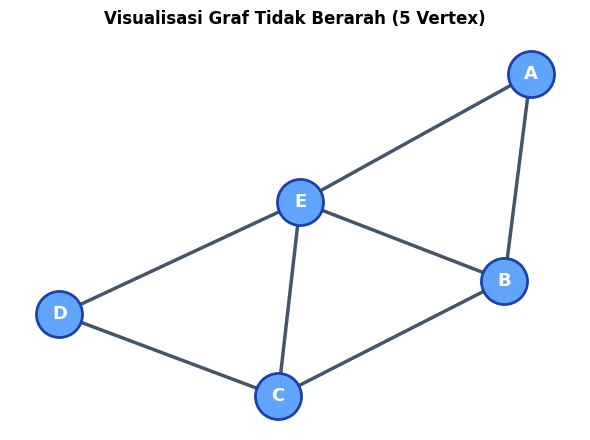

In [2]:
# Inisialisasi graf tidak berarah
G = nx.Graph()

# 5 simpul (vertex)
vertices = ['A', 'B', 'C', 'D', 'E']
G.add_nodes_from(vertices)

# Sisi  
edges = [
    ('A', 'B'),
    ('A', 'E'),
    ('B', 'C'),
    ('B', 'E'),
    ('C', 'D'),
    ('C', 'E'),
    ('D', 'E')
]
G.add_edges_from(edges)

# Visualisasi Graf
plt.figure(figsize=(6, 4.5))
pos = nx.spring_layout(G, seed=42)
nx.draw_networkx_nodes(G, pos, node_size=1100, node_color='#60a5fa', edgecolors='#1e40af', linewidths=2)
nx.draw_networkx_edges(G, pos, width=2.5, edge_color='#475569')
nx.draw_networkx_labels(G, pos, font_size=13, font_weight='bold', font_color='#ffffff')
plt.title("Visualisasi Graf Tidak Berarah (5 Vertex)", fontsize=12, fontweight='bold', pad=12)
plt.axis('off')
plt.tight_layout()
plt.show()

--- 
## 2. Perhitungan 8 Karakteristik Graf Tidak Berarah

In [4]:
N = G.number_of_nodes()  # Jumlah vertex (5)
E = G.number_of_edges()  # Jumlah edge (7)

# 1. HITUNG DEGREE (DERAJAT TIAP SIMPUL)
degrees = dict(G.degree())
print("1. DEGREE (DERAJAT TIAP SIMPUL):")
for node, deg in degrees.items():
    tetangga = list(G.neighbors(node))
    print(f"   Simpul {node} : Degree = {deg} (terhubung ke {tetangga})")
print(f"   Total Derajat (sum) = {sum(degrees.values())}  [Rumus: 2 * E = 2 * {E} = {2 * E}]")

# 2. HITUNG DISTRIBUSI DERAJAT: P(k) = N_k / N
deg_counts = Counter(degrees.values())
deg_distribution = {k: count / N for k, count in sorted(deg_counts.items())}
print("\n2. DISTRIBUSI DERAJAT P(k):")
for k, prob in deg_distribution.items():
    print(f"   P(k = {k}) = {deg_counts[k]}/{N} = {prob:.2f} ({prob * 100:.1f}%)")

# 3. HITUNG AVERAGE DEGREE: <k> = sum(k) / N atau 2E / N
avg_degree = sum(degrees.values()) / N
print(f"\n3. AVERAGE DEGREE: <k> = {sum(degrees.values())}/{N} = {avg_degree:.2f}")

# 4. HITUNG DENSITY (KEPADATAN GRAF): 2E / [N(N-1)]
density_manual = (2 * E) / (N * (N - 1))
density_nx = nx.density(G)
print(f"\n4. DENSITY (KEPADATAN GRAF):")
print(f"   Rumus: 2 * E / [N * (N - 1)] = (2 * {E}) / ({N} * {N-1}) = {2*E}/{N*(N-1)} = {density_manual:.2f}")
print(f"   Hasil nx.density(G) = {density_nx:.2f} ({density_nx * 100:.1f}%)")

# 5. HITUNG KOEFISIEN KLASTERISASI (CLUSTERING COEFFICIENT)
clustering_local = nx.clustering(G)
avg_clustering = nx.average_clustering(G)
print("\n5. KOEFISIEN KLASTERISASI (CLUSTERING COEFFICIENT):")
print("   Koefisien Klasterisasi tiap simpul (C_i):")
for node, c in clustering_local.items():
    print(f"      Simpul {node} : C_{node} = {c:.4f}")
print(f"   Rata-rata Koefisien Klasterisasi <C> = {avg_clustering:.4f}")

# 6. JALUR TERPENDEK (SHORTEST PATH)
all_paths = dict(nx.all_pairs_shortest_path(G))
all_lengths = dict(nx.all_pairs_shortest_path_length(G))

print("\n6. JALUR TERPENDEK (SHORTEST PATH ANTAR-SIMPUL):")
for u in vertices:
    for v in vertices:
        if u < v:  # Tampilkan pasangan unik untuk graf tidak berarah
            path = all_paths[u][v]
            dist = all_lengths[u][v]
            print(f"   Jalur {u} <-> {v} : {' - '.join(path)} (Jarak = {dist})")

# Matriks Jarak Jalur Terpendek
df_dist_matrix = pd.DataFrame(all_lengths).sort_index()[vertices].reindex(vertices)

# 7. HITUNG DIAMETER JARINGAN & JARAK RATA-RATA
if nx.is_connected(G):
    diameter = nx.diameter(G)
    avg_distance = nx.average_shortest_path_length(G)
    print("\n7. DIAMETER JARINGAN & JARAK RATA-RATA:")
    print(f"   Diameter Jaringan (Jarak terpanjang terpendek) = {diameter}")
    print(f"   Jarak Rata-rata Antar-simpul (Avg Path Length) = {avg_distance:.4f}")
else:
    print("\n7. Graf tidak terhubung sepenuhnya, diameter tidak dapat dihitung.")

# 8. TAMPILKAN MATRIKS ADJACENCY (KETETANGGAAN)
adj_matrix = nx.to_pandas_adjacency(G, nodelist=vertices, dtype=int)
print("\n8. MATRIKS ADJACENCY (KETETANGGAAN):")
display(adj_matrix)


1. DEGREE (DERAJAT TIAP SIMPUL):
   Simpul A : Degree = 2 (terhubung ke ['B', 'E'])
   Simpul B : Degree = 3 (terhubung ke ['A', 'C', 'E'])
   Simpul C : Degree = 3 (terhubung ke ['B', 'D', 'E'])
   Simpul D : Degree = 2 (terhubung ke ['C', 'E'])
   Simpul E : Degree = 4 (terhubung ke ['A', 'B', 'C', 'D'])
   Total Derajat (sum) = 14  [Rumus: 2 * E = 2 * 7 = 14]

2. DISTRIBUSI DERAJAT P(k):
   P(k = 2) = 2/5 = 0.40 (40.0%)
   P(k = 3) = 2/5 = 0.40 (40.0%)
   P(k = 4) = 1/5 = 0.20 (20.0%)

3. AVERAGE DEGREE: <k> = 14/5 = 2.80

4. DENSITY (KEPADATAN GRAF):
   Rumus: 2 * E / [N * (N - 1)] = (2 * 7) / (5 * 4) = 14/20 = 0.70
   Hasil nx.density(G) = 0.70 (70.0%)

5. KOEFISIEN KLASTERISASI (CLUSTERING COEFFICIENT):
   Koefisien Klasterisasi tiap simpul (C_i):
      Simpul A : C_A = 1.0000
      Simpul B : C_B = 0.6667
      Simpul C : C_C = 0.6667
      Simpul D : C_D = 1.0000
      Simpul E : C_E = 0.5000
   Rata-rata Koefisien Klasterisasi <C> = 0.7667

6. JALUR TERPENDEK (SHORTEST PATH AN

,A,B,C,D,E
A,0,1,0,0,1
B,1,0,1,0,1
C,0,1,0,1,1
D,0,0,1,0,1
E,1,1,1,1,0
